# Bài 2 (Trang 32): Tính giá trị F-measure của các bài tập cơ bản
**Sinh viên:** Trần Nhất Long - 6451071042

Công thức:
$$F\text{-measure} = 2 \times \frac{\text{precision} \times \text{recall}}{\text{precision} + \text{recall}}$$

In [1]:
%matplotlib inline
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

print("Trần Nhất Long - 6451071042")

def f_measure(precision, recall):
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)

Trần Nhất Long - 6451071042


## Phần 1: Bài tập cơ bản - Mục III.1 (Trang 1 - 15): Đánh giá rủi ro hồ sơ vay tín dụng

In [2]:
print("Trần Nhất Long - 6451071042")
# Theo kết quả ma trận nhầm lẫn ở trang 11 và trang 15 (lớp dương = 'Rủi ro thấp'):
# Cây quyết định (ID3 / CART): TP=2, FP=1, FN=0, TN=0 -> Precision = 2/3, Recall = 2/2 = 1.0
# Naïve Bayes (Laplace):       TP=2, FP=0, FN=0, TN=1 -> Precision = 2/2 = 1.0, Recall = 2/2 = 1.0

p_tree, r_tree = 2 / 3, 2 / 2
f_tree = f_measure(p_tree, r_tree)

p_nb, r_nb = 2 / 2, 2 / 2
f_nb = f_measure(p_nb, r_nb)

df_p1 = pd.DataFrame([
    {"Bài tập": "III.1 Tín dụng", "Mô hình": "Cây quyết định (ID3/CART)", "Precision": p_tree, "Recall": r_tree, "F-measure": f_tree},
    {"Bài tập": "III.1 Tín dụng", "Mô hình": "Naïve Bayes (Laplace)", "Precision": p_nb, "Recall": r_nb, "F-measure": f_nb},
])
print(df_p1.to_string(index=False))

Trần Nhất Long - 6451071042
       Bài tập                   Mô hình  Precision  Recall  F-measure
III.1 Tín dụng Cây quyết định (ID3/CART)   0.666667     1.0        0.8
III.1 Tín dụng     Naïve Bayes (Laplace)   1.000000     1.0        1.0


## Phần 2: Bài tập cơ bản - Mục IV.1 (Trang 23 - 25): Dự đoán doanh số bán đồ chơi trẻ em

In [3]:
print("Trần Nhất Long - 6451071042")
# Dữ liệu huấn luyện (15 dòng - Trang 24)
train_toys = pd.DataFrame([
    ["Điều khiển", "3", "Nhỏ", "Nhựa PP", "Cao"],
    ["Xếp hình",   "5", "Vừa", "Cao su",  "Thấp"],
    ["Xếp hình",   "7", "To",  "Nhựa PP", "Thấp"],
    ["Điều khiển", "5", "Nhỏ", "Cao su",  "Thấp"],
    ["Búp bê",     "3", "Vừa", "Nhựa PP", "Thấp"],
    ["Điều khiển", "5", "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê",     "5", "To",  "Nhựa PP", "Cao"],
    ["Điều khiển", "7", "Vừa", "Cao su",  "Thấp"],
    ["Xếp hình",   "7", "To",  "Cao su",  "Cao"],
    ["Xếp hình",   "3", "To",  "Nhựa PP", "Thấp"],
    ["Búp bê",     "3", "Nhỏ", "Cao su",  "Thấp"],
    ["Xếp hình",   "3", "Nhỏ", "Nhựa PP", "Cao"],
    ["Điều khiển", "5", "To",  "Cao su",  "Thấp"],
    ["Búp bê",     "5", "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê",     "7", "To",  "Nhựa PP", "Cao"],
], columns=["Loại", "Số màu", "Kích thước", "Chất liệu", "Doanh số bán"])

# Dữ liệu kiểm thử (3 dòng - Trang 24) và nhãn thực tế (Trang 24: Thấp, Thấp, Cao)
test_toys = pd.DataFrame([
    ["Búp bê",     "3", "To",  "Cao su"],
    ["Xếp hình",   "5", "To",  "Nhựa PP"],
    ["Điều khiển", "3", "Vừa", "Cao su"],
], columns=["Loại", "Số màu", "Kích thước", "Chất liệu"])
y_true_toys = ["Thấp", "Thấp", "Cao"]

# Kiểm tra mâu thuẫn
dups = train_toys.groupby(["Loại", "Số màu", "Kích thước", "Chất liệu"])["Doanh số bán"].nunique()
print("Số mâu thuẫn trong dữ liệu đồ chơi:", int((dups > 1).sum()))

# Cài đặt ID3 (Information Gain) và CART (Gini) cho dữ liệu phân loại (categorical)
def entropy(y):
    n = len(y)
    return -sum((c / n) * math.log2(c / n) for c in Counter(y).values())

def gini(y):
    n = len(y)
    return 1.0 - sum((c / n) ** 2 for c in Counter(y).values())

def build_cat_tree(df, features, target, criterion="id3"):
    y = df[target].tolist()
    if len(set(y)) == 1:
        return y[0]
    if not features:
        return Counter(y).most_common(1)[0][0]
    n = len(df)
    best_feat, best_score = None, (-1e9 if criterion == "id3" else 1e9)
    base_ent = entropy(y)
    for f in features:
        groups = df.groupby(f)
        if criterion == "id3":
            rem = sum((len(g) / n) * entropy(g[target].tolist()) for _, g in groups)
            score = base_ent - rem
            if score > best_score:
                best_score, best_feat = score, f
        else:
            g_idx = sum((len(g) / n) * gini(g[target].tolist()) for _, g in groups)
            if g_idx < best_score:
                best_score, best_feat = g_idx, f
    tree_node = {"feature": best_feat, "default": Counter(y).most_common(1)[0][0], "branches": {}}
    rem_feats = [f for f in features if f != best_feat]
    for val, g in df.groupby(best_feat):
        tree_node["branches"][val] = build_cat_tree(g, rem_feats, target, criterion)
    return tree_node

def predict_cat_tree(tree_node, row):
    if not isinstance(tree_node, dict):
        return tree_node
    val = row[tree_node["feature"]]
    if val in tree_node["branches"]:
        return predict_cat_tree(tree_node["branches"][val], row)
    return tree_node["default"]

def predict_nb_laplace(df, features, target, test_df):
    classes = sorted(df[target].unique())
    n = len(df)
    k_cls = len(classes)
    preds = []
    for _, row in test_df.iterrows():
        best_c, best_p = None, -1.0
        for c in classes:
            sub = df[df[target] == c]
            p = (len(sub) + 1) / (n + k_cls)
            for f in features:
                k_val = df[f].nunique()
                cnt = (sub[f] == row[f]).sum()
                p *= (cnt + 1) / (len(sub) + k_val)
            if p > best_p:
                best_p, best_c = p, c
        preds.append(best_c)
    return preds

feats_toys = ["Loại", "Số màu", "Kích thước", "Chất liệu"]
tree_id3_toys = build_cat_tree(train_toys, feats_toys, "Doanh số bán", "id3")
tree_cart_toys = build_cat_tree(train_toys, feats_toys, "Doanh số bán", "cart")

pred_id3_toys = [predict_cat_tree(tree_id3_toys, r) for _, r in test_toys.iterrows()]
pred_cart_toys = [predict_cat_tree(tree_cart_toys, r) for _, r in test_toys.iterrows()]
pred_nb_toys = predict_nb_laplace(train_toys, feats_toys, "Doanh số bán", test_toys)

print("Thực tế:    ", y_true_toys)
print("ID3 dự đoán:", pred_id3_toys)
print("CART dự đoán:", pred_cart_toys)
print("NB dự đoán: ", pred_nb_toys)

# Tính Precision, Recall, F-measure (lớp dương = 'Cao')
def binary_metrics(y_true, y_pred, pos_label="Cao"):
    tp = sum(t == pos_label and p == pos_label for t, p in zip(y_true, y_pred))
    fp = sum(t != pos_label and p == pos_label for t, p in zip(y_true, y_pred))
    fn = sum(t == pos_label and p != pos_label for t, p in zip(y_true, y_pred))
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    return prec, rec, f_measure(prec, rec)

rows_toys = []
for mname, pred in [("ID3", pred_id3_toys), ("CART", pred_cart_toys), ("Naïve Bayes (Laplace)", pred_nb_toys)]:
    p_thap, r_thap, fm_thap = binary_metrics(y_true_toys, pred, pos_label="Thấp")
    p_cao, r_cao, fm_cao = binary_metrics(y_true_toys, pred, pos_label="Cao")
    rows_toys.append({"Bài tập": "IV.1 Đồ chơi (lớp dương: Thấp)", "Mô hình": mname, "Precision": p_thap, "Recall": r_thap, "F-measure": fm_thap})
    rows_toys.append({"Bài tập": "IV.1 Đồ chơi (lớp dương: Cao)", "Mô hình": mname, "Precision": p_cao, "Recall": r_cao, "F-measure": fm_cao})

df_toys = pd.DataFrame(rows_toys)
print("\nKết quả bài IV.1:")
print(df_toys.to_string(index=False))

Trần Nhất Long - 6451071042
Số mâu thuẫn trong dữ liệu đồ chơi: 0
Thực tế:     ['Thấp', 'Thấp', 'Cao']
ID3 dự đoán: ['Thấp', 'Thấp', 'Thấp']
CART dự đoán: ['Thấp', 'Thấp', 'Thấp']
NB dự đoán:  ['Thấp', 'Cao', 'Thấp']

Kết quả bài IV.1:
                       Bài tập               Mô hình  Precision  Recall  F-measure
IV.1 Đồ chơi (lớp dương: Thấp)                   ID3   0.666667     1.0        0.8
 IV.1 Đồ chơi (lớp dương: Cao)                   ID3   0.000000     0.0        0.0
IV.1 Đồ chơi (lớp dương: Thấp)                  CART   0.666667     1.0        0.8
 IV.1 Đồ chơi (lớp dương: Cao)                  CART   0.000000     0.0        0.0
IV.1 Đồ chơi (lớp dương: Thấp) Naïve Bayes (Laplace)   0.500000     0.5        0.5
 IV.1 Đồ chơi (lớp dương: Cao) Naïve Bayes (Laplace)   0.000000     0.0        0.0


## Phần 3: Bài tập cơ bản - Mục IV.2 (Trang 25 - 26): Phân tích cảm xúc (Sentiment Analysis)

In [4]:
print("Trần Nhất Long - 6451071042")
# Dữ liệu huấn luyện (14 dòng - Trang 25)
cols_sent = ["giảm", "người", "chuyển", "yêu", "vừa", "đi", "Cảm xúc"]
train_sent = pd.DataFrame([
    ["0..5",   "11..20", ">20",    "11..20", ">20",    "0..5",   "tốt"],
    ["11..20", "6..10",  "6..10",  "0..5",   "11..20", "11..20", "tốt"],
    ["6..10",  "0..5",   "6..10",  "11..20", "0..5",   "6..10",  "xấu"],
    [">20",    "0..5",   "11..20", "6..10",  "0..5",   ">20",    "bình thường"],
    ["0..5",   ">20",    "11..20", "0..5",   "6..10",  "0..5",   "xấu"],
    ["0..5",   "6..10",  "0..5",   "0..5",   "11..20", "11..20", "xấu"],
    ["0..5",   "6..10",  "11..20", "0..5",   "6..10",  "0..5",   "tốt"],
    ["11..20", ">20",    "0..5",   "11..20", "0..5",   "11..20", "bình thường"],
    ["0..5",   "0..5",   "6..10",  "6..10",  "6..10",  ">20",    "tốt"],
    ["11..20", "0..5",   "11..20", "11..20", "0..5",   "11..20", "tốt"],
    [">20",    "6..10",  "0..5",   "0..5",   "0..5",   "6..10",  "xấu"],
    ["0..5",   "0..5",   "11..20", "0..5",   "11..20", ">20",    "bình thường"],
    ["6..10",  "11..20", "6..10",  ">20",    "0..5",   "6..10",  "bình thường"],
    ["11..20", "6..10",  ">20",    "11..20", "0..5",   "0..5",   "xấu"],
], columns=cols_sent)

# Dữ liệu kiểm thử (4 dòng - Trang 26) và nhãn thực tế: xấu, tốt, bình thường, tốt
feats_sent = ["giảm", "người", "chuyển", "yêu", "vừa", "đi"]
test_sent = pd.DataFrame([
    ["0..5",  "6..10",  "0..5",   "11..20", "6..10",  "0..5"],
    ["0..5",  "0..5",   "6..10",  "0..5",   "11..20", ">20"],
    ["6..10", "0..5",   "11..20", ">20",    "6..10",  "6..10"],
    ["6..10", "11..20", "6..10",  "6..10",  ">20",    "0..5"],
], columns=feats_sent)
y_true_sent = ["xấu", "tốt", "bình thường", "tốt"]

dups_sent = train_sent.groupby(feats_sent)["Cảm xúc"].nunique()
print("Số mâu thuẫn trong dữ liệu cảm xúc:", int((dups_sent > 1).sum()))

tree_cart_sent = build_cat_tree(train_sent, feats_sent, "Cảm xúc", "cart")
pred_cart_sent = [predict_cat_tree(tree_cart_sent, r) for _, r in test_sent.iterrows()]
pred_nb_sent = predict_nb_laplace(train_sent, feats_sent, "Cảm xúc", test_sent)

print("Thực tế:     ", y_true_sent)
print("CART dự đoán:", pred_cart_sent)
print("NB dự đoán:  ", pred_nb_sent)

from sklearn import metrics
classes_sent = ["tốt", "bình thường", "xấu"]
rows_sent = []
for mname, pred in [("CART (Gini)", pred_cart_sent), ("Naïve Bayes (Laplace)", pred_nb_sent)]:
    p_macro = metrics.precision_score(y_true_sent, pred, labels=classes_sent, average="macro", zero_division=0)
    r_macro = metrics.recall_score(y_true_sent, pred, labels=classes_sent, average="macro", zero_division=0)
    f_macro = f_measure(p_macro, r_macro)
    f1_sk = metrics.f1_score(y_true_sent, pred, labels=classes_sent, average="macro", zero_division=0)
    print(f"\n--- {mname} ---")
    print("Ma trận nhầm lẫn (hàng=thực tế, cột=dự đoán; thứ tự: tốt, bình thường, xấu):")
    print(metrics.confusion_matrix(y_true_sent, pred, labels=classes_sent))
    print(metrics.classification_report(y_true_sent, pred, labels=classes_sent, zero_division=0))
    rows_sent.append({
        "Bài tập": "IV.2 Cảm xúc (Macro)",
        "Mô hình": mname,
        "Precision": p_macro,
        "Recall": r_macro,
        "F-measure": f1_sk,
    })

df_sent = pd.DataFrame(rows_sent)

Trần Nhất Long - 6451071042
Số mâu thuẫn trong dữ liệu cảm xúc: 0
Thực tế:      ['xấu', 'tốt', 'bình thường', 'tốt']
CART dự đoán: ['tốt', 'tốt', 'xấu', 'tốt']
NB dự đoán:   ['xấu', 'tốt', 'bình thường', 'tốt']



--- CART (Gini) ---
Ma trận nhầm lẫn (hàng=thực tế, cột=dự đoán; thứ tự: tốt, bình thường, xấu):
[[2 0 0]
 [0 0 1]
 [1 0 0]]
              precision    recall  f1-score   support

         tốt       0.67      1.00      0.80         2
 bình thường       0.00      0.00      0.00         1
         xấu       0.00      0.00      0.00         1

    accuracy                           0.50         4
   macro avg       0.22      0.33      0.27         4
weighted avg       0.33      0.50      0.40         4


--- Naïve Bayes (Laplace) ---
Ma trận nhầm lẫn (hàng=thực tế, cột=dự đoán; thứ tự: tốt, bình thường, xấu):
[[2 0 0]
 [0 1 0]
 [0 0 1]]
              precision    recall  f1-score   support

         tốt       1.00      1.00      1.00         2
 bình thường       1.00      1.00      1.00         1
         xấu       1.00      1.00      1.00         1

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.

## Tổng hợp giá trị F-measure của các bài tập cơ bản

Trần Nhất Long - 6451071042
                       Bài tập                   Mô hình  Precision   Recall  F-measure
                III.1 Tín dụng Cây quyết định (ID3/CART)   0.666667 1.000000   0.800000
                III.1 Tín dụng     Naïve Bayes (Laplace)   1.000000 1.000000   1.000000
IV.1 Đồ chơi (lớp dương: Thấp)                       ID3   0.666667 1.000000   0.800000
 IV.1 Đồ chơi (lớp dương: Cao)                       ID3   0.000000 0.000000   0.000000
IV.1 Đồ chơi (lớp dương: Thấp)                      CART   0.666667 1.000000   0.800000
 IV.1 Đồ chơi (lớp dương: Cao)                      CART   0.000000 0.000000   0.000000
IV.1 Đồ chơi (lớp dương: Thấp)     Naïve Bayes (Laplace)   0.500000 0.500000   0.500000
 IV.1 Đồ chơi (lớp dương: Cao)     Naïve Bayes (Laplace)   0.000000 0.000000   0.000000
          IV.2 Cảm xúc (Macro)               CART (Gini)   0.222222 0.333333   0.266667
          IV.2 Cảm xúc (Macro)     Naïve Bayes (Laplace)   1.000000 1.000000   1.000000


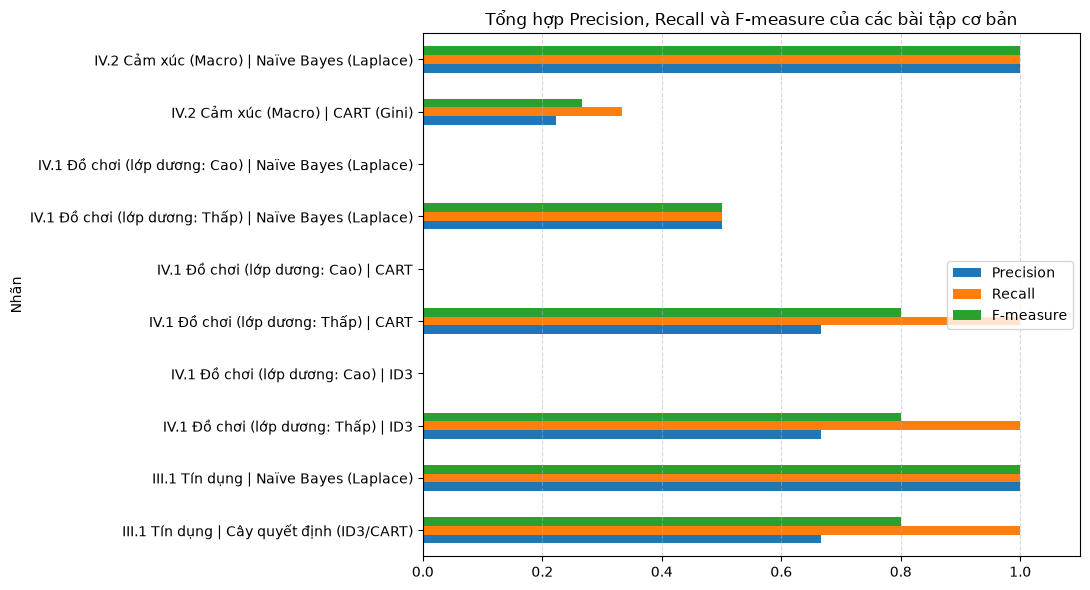

In [5]:
print("Trần Nhất Long - 6451071042")
df_all = pd.concat([df_p1, df_toys, df_sent], ignore_index=True)
print(df_all.to_string(index=False))

df_all["Nhãn"] = df_all["Bài tập"] + " | " + df_all["Mô hình"]
ax = df_all.set_index("Nhãn")[["Precision", "Recall", "F-measure"]].plot(kind="barh", figsize=(11, 6), xlim=(0, 1.1))
plt.title("Tổng hợp Precision, Recall và F-measure của các bài tập cơ bản")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()